# Finite-Stratum Transport

## Standardization Across Populations

Let $S_i=1$ identify a unit in the source population and let $S_i=0$ identify a unit in the target population. A categorical modifier $G_i$ places each unit in one of $K$ strata. For treatment level $a\in\{0,1\}$, define the source conditional potential-outcome mean by

$$
\mu_a^S(g)=\mathbb E\left[Y_i(a)\mid G_i=g,S_i=1\right].
$$

Here, $Y_i(a)$ is the potential outcome under treatment level $a$, and $\mu_a^S(g)$ is its source mean within stratum $g$. The source conditional effect is

$$
\tau^S(g)=\mu_1^S(g)-\mu_0^S(g).
$$

Let $\pi_g^T=\Pr(G_i=g\mid S_i=0)$ be the target share in stratum $g$. When the stated transport assumptions hold, the target average effect is given by

$$
\tau^T=\sum_{g=1}^{K}\pi_g^T\tau^S(g).
$$

The weights $\pi_g^T$ are nonnegative and sum to one. This formula is finite-stratum standardization. The calculation itself cannot establish exchangeability, consistency, shared treatment definitions, or transportability of the conditional means.

### Evaluating transport under explicit assumptions

The source must contain both treatment groups in every stratum with positive target probability. A stratum with zero target probability contributes zero, but all supplied means must still be finite. The following exact calculation reproduces the released RiskLabAI contract before any public data are used.

#### Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("06_transportability");
using CSV, TOML, Printf
using RiskLabAI.CausalFactorAnalysis: transported_ate
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore, normal_block
include(joinpath("..","support","BookSensitivityStudy.jl"))
include(joinpath("..","support","BookTransportStudy.jl"))
using .BookTransportStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter06_random_inputs"),"transport")
captions=Dict("transport_notation"=>"Notation for finite-stratum transport.","transport_assumption_ledger"=>"Assumption ledger for finite-stratum standardization.","transport_exact_inputs"=>"Inputs for the released exact standardization calculation.","transport_exact_contributions"=>"Stratum contributions to the exact target effect.","transport_exact_check"=>"Exact standardization identity check.","transport_public_provenance"=>"Provenance of the public panel used for descriptive standardization.","transport_public_domains"=>"Source and target domains in the public county calculation.","transport_public_strata"=>"Source outcomes, support counts, and target weights by baseline-employment stratum.","transport_public_support_book"=>"Public support counts and population weights by stratum.","transport_public_contrasts_book"=>"Public source means and contrasts by stratum.","transport_public_effects"=>"Descriptive public source and target comparisons.","transport_public_decomposition"=>"Decomposition of the public source-to-target weight change.","transport_public_decomposition_book"=>"Readable decomposition of the public source-to-target weight change.","transport_public_decomposition_check"=>"Checks for the public weight-shift decomposition.","transport_public_boundaries"=>"Interpretive limits of the public standardization.","support_partition_summary"=>"Support audit as the public baseline partition becomes finer.","support_partition_summary_book"=>"Readable support audit as the public partition becomes finer.","support_primary_terciles"=>"Support audit for the approved three-stratum public calculation.","support_quartile_audit"=>"Four-stratum audit showing the first public support failure.","support_public_failure_record"=>"Recorded failure for the unsupported four-stratum public calculation.","support_target_weight_path"=>"Target-weight path from the public source mix to the public target mix.","support_target_weight_path_selected"=>"Selected points on the public target-weight path.","support_target_weight_path_book"=>"Readable points on the public target-weight path.","support_simplex_extrema"=>"Selected points on the target-weight simplex.","support_zero_mass_contract"=>"Zero-target-mass and positive-target-mass calculations.","support_invalid_input_checks"=>"Explicit input and support failures.","support_invalid_input_checks_book"=>"Plain-language input and support checks.","support_section_summary"=>"Summary of target weights and support checks.","recovery_generated_design"=>"Declared design for the generated transport experiment.","recovery_generated_contract"=>"Scope of the generated transport experiment.","recovery_domain_weights"=>"Generated source and target stratum weights.","recovery_stratum_effects"=>"Known and recovered effects in each generated stratum.","recovery_primary_check"=>"Exact known-truth recovery in the generated design.","recovery_estimate_comparison"=>"Generated estimates under correct, coarsened, and omitted modifiers.","recovery_coarse_strata"=>"Coarsened modifier calculation in the generated design.","recovery_target_mix_path"=>"Generated truth and estimates as the target composition changes.","recovery_target_mix_selected"=>"Selected points on the generated target-composition path.","recovery_target_mix_book"=>"Readable points on the generated target-composition path.","recovery_support_cases"=>"Generated support success and failure cases.","recovery_support_cases_book"=>"Plain-language generated support cases.","recovery_invalid_input_checks"=>"Generated-design input validation checks.","recovery_invalid_input_checks_book"=>"Plain-language generated-design input checks.","recovery_section_summary"=>"Summary of generated recovery and failure results.")
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption=captions[name],label="tab:cim6-"*replace(name,"_"=>"-"))
    return nothing
end;


#### Target Effect as a Sum of Stratum Contributions

Row,Symbol,Description
,String,String
1,S_i,Population indicator: one for source and zero for target
2,G_i,Finite stratum containing unit i
3,Y_i(a),Potential outcome for unit i under treatment level a
4,mu_a^S(g),Source mean potential outcome under treatment a in stratum g
5,tau^S(g),Source treatment contrast in stratum g
6,pi_g^T,Target probability of stratum g
7,tau^T,Target average treatment effect under the stated assumptions


Row,Requirement,Role,Checked by calculation
,String,String,String
1,Source treatment exchangeability,Connects source treatment groups to source conditional potential-outcome means,Not checked
2,Consistency,Connects observed outcomes to the treatment actually received,Not checked
3,Shared definitions,Keeps treatment and outcome meanings aligned across populations,Not checked
4,Conditional mean transportability,Carries stratum-specific potential-outcome means from source to target,Not checked
5,Source support where target probability is positive,Requires both source treatment groups wherever target probability is positive,Checked


Row,Stratum,Treated mean,Control mean,Stratum effect,Target probability,Treated source count,Control source count
,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,1,2.0,1.0,1.0,0.25,2.0,3.0
2,2,4.0,2.0,2.0,0.75,4.0,7.0
3,3,8.0,9.0,-1.0,0.0,0.0,0.0


Row,Stratum,Stratum effect,Target probability,Target contribution
,Int64,Float64,Float64,Float64
1,1,1.0,0.25,0.25
2,2,2.0,0.75,1.5
3,3,-1.0,0.0,-0.0


Row,Quantity,Value
,String,Float64
1,Released calculation,1.75
2,Direct weighted sum,1.75
3,Absolute difference,0.0


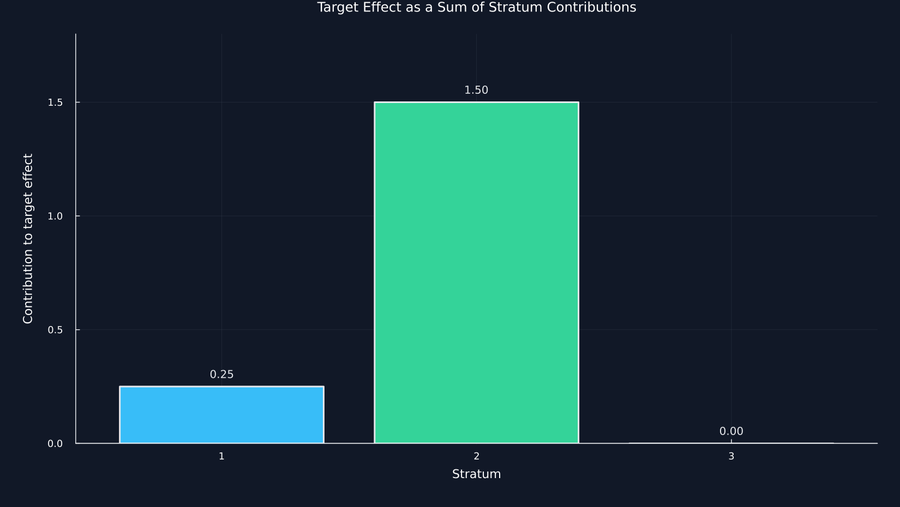

In [1]:
notation = frame(["Symbol","Description"],[["S_i","Population indicator: one for source and zero for target"],["G_i","Finite stratum containing unit i"],["Y_i(a)","Potential outcome for unit i under treatment level a"],["mu_a^S(g)","Source mean potential outcome under treatment a in stratum g"],["tau^S(g)","Source treatment contrast in stratum g"],["pi_g^T","Target probability of stratum g"],["tau^T","Target average treatment effect under the stated assumptions"]])
table(notation,"transport_notation")
assumptions = frame(["Requirement","Role","Checked by calculation"],[["Source treatment exchangeability","Connects source treatment groups to source conditional potential-outcome means","Not checked"],["Consistency","Connects observed outcomes to the treatment actually received","Not checked"],["Shared definitions","Keeps treatment and outcome meanings aligned across populations","Not checked"],["Conditional mean transportability","Carries stratum-specific potential-outcome means from source to target","Not checked"],["Source support where target probability is positive","Requires both source treatment groups wherever target probability is positive","Checked"]])
table(assumptions,"transport_assumption_ledger")
treated_means=[2.,4.,8.]
control_means=[1.,2.,9.]
target_probabilities=[.25,.75,0.]
source_treated_counts=[2.,4.,0.]
source_control_counts=[3.,7.,0.]
stratum_effects=treated_means-control_means
contributions=target_probabilities.*stratum_effects
exact_transport=transported_ate(treated_means,control_means,target_probabilities,source_treated_counts,source_control_counts)
@assert isapprox(exact_transport,1.75)
exact_inputs=DataFrame("Stratum"=>1:3,"Treated mean"=>treated_means,"Control mean"=>control_means,"Stratum effect"=>stratum_effects,"Target probability"=>target_probabilities,"Treated source count"=>source_treated_counts,"Control source count"=>source_control_counts)
table(exact_inputs,"transport_exact_inputs")
exact_contributions=exact_inputs[:,["Stratum","Stratum effect","Target probability"]]
exact_contributions[!,"Target contribution"]=contributions
table(exact_contributions,"transport_exact_contributions")
exact_check=frame(["Quantity","Value"],[("Released calculation",exact_transport),("Direct weighted sum",sum(contributions)),("Absolute difference",abs(exact_transport-sum(contributions)))])
table(exact_check,"transport_exact_check")
save_data(exact_contributions,paths,"transport_exact_contributions")
figure=bar(1:3,contributions;xticks=(1:3,string.(1:3)),color=[palette.cyan,palette.green,palette.amber],xlabel="Stratum",ylabel="Contribution to target effect",title="Target Effect as a Sum of Stratum Contributions",legend=false,ylims=(0,1.8),size=(1100,620))
for (index,value) in enumerate(contributions)
    annotate!(figure,index,value+.055,text(@sprintf("%.2f",iszero(value) ? 0. : value),9,palette.text))
end
hline!(figure,[0.];color=palette.text,linewidth=.9,label="")
save_figure(figure,paths,"transport_exact_contributions")


## A Descriptive Public County Standardization

The public calculation uses one row per county. Counties at or below the median 2003 log population form the source domain, and counties above the median form the target domain. Terciles of 2003 log employment define the strata. Treatment is the panel's fixed treated-group indicator, and the outcome is the change in log employment from 2003 to 2007.

This calculation shows how standardization changes when target weights differ from source weights. It is descriptive. It does not identify a transported causal minimum-wage effect because the scientific assumptions are not established by the panel.

Row,Item,Value
,String,Any
1,Public source,Callaway and Sant'Anna county panel
2,Local file,data/public/callaway_santanna/mpdta.csv
3,File bytes,124867
4,Panel rows,2500
5,Counties,500
6,Download during execution,None


Row,Domain,Counties,Treated,Mean baseline log population,Mean baseline log employment,Mean employment change
,String,Int64,Int64,Float64,Float64,Float64
1,Source,250,80,2.31107,4.72875,-0.0327768
2,Target,250,111,4.31475,6.86827,0.0163391


Row,Stratum,Stratum name,Source control count,Source treated count,Source control mean,Source treated mean,Source contrast,Source probability,Target count,Target probability
,Int64,String,Int64,Int64,Float64,Float64,Float64,Float64,Int64,Float64
1,0,Low,116,47,-0.0051387,-0.0282596,-0.0231209,0.652,4,0.016
2,1,Middle,49,32,-0.0497982,-0.11837,-0.0685717,0.324,85,0.34
3,2,High,5,1,-0.0189725,0.0529049,0.0718774,0.024,161,0.644


Row,Stratum name,Source control count,Source treated count,Source probability,Target count,Target probability
,String,Int64,Int64,Float64,Int64,Float64
1,Low,116,47,0.652,4,0.016
2,Middle,49,32,0.324,85,0.34
3,High,5,1,0.024,161,0.644


Row,Stratum name,Source control mean,Source treated mean,Source contrast
,String,Float64,Float64,Float64
1,Low,-0.0051387,-0.0282596,-0.0231209
2,Middle,-0.0497982,-0.11837,-0.0685717
3,High,-0.0189725,0.0529049,0.0718774


Row,Calculation,Value,Interpretation
,String,Float64,String
1,Source-stratum weights,-0.035567,Descriptive source standardization
2,Target-stratum weights,0.0226047,Descriptive target standardization
3,Raw source group difference,-0.0448712,Unadjusted source comparison
4,Raw target group difference,-0.0464906,Unadjusted target comparison


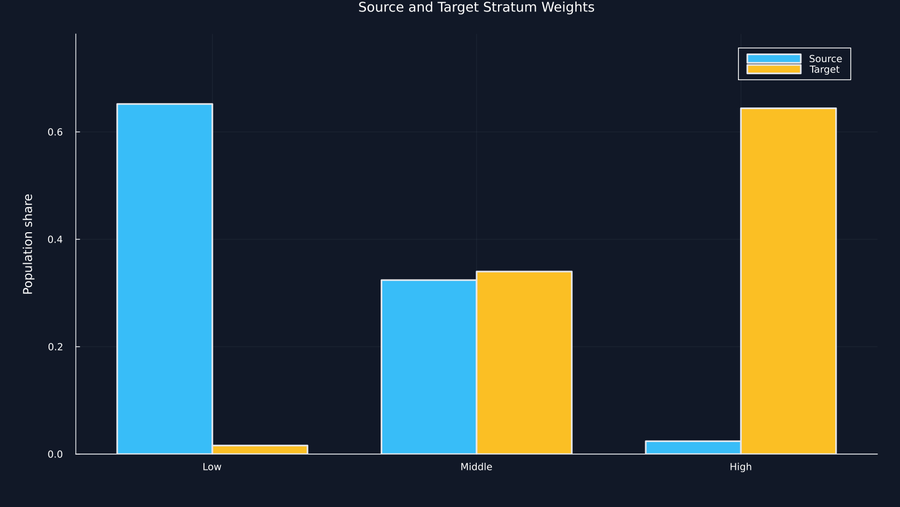

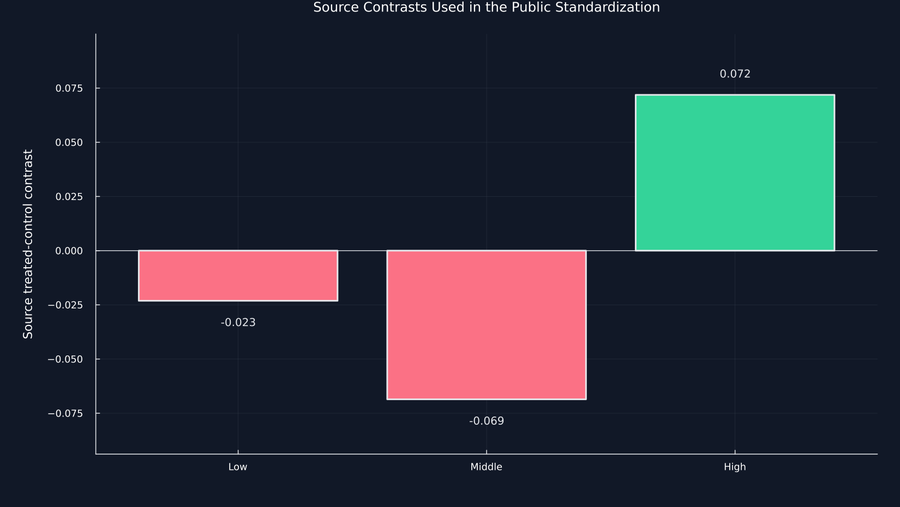

In [2]:
raw,counties,population_median=transport_counties()
@assert nrow(raw)==2500 && nrow(counties)==500
data_file=joinpath(book_root(),"data","public","callaway_santanna","mpdta.csv")
provenance=frame(["Item","Value"],[("Public source","Callaway and Sant'Anna county panel"),("Local file","data/public/callaway_santanna/mpdta.csv"),("File bytes",filesize(data_file)),("Panel rows",nrow(raw)),("Counties",nrow(counties)),("Download during execution","None")])
table(provenance,"transport_public_provenance")
domain_summary=frame(["Domain","Counties","Treated","Mean baseline log population","Mean baseline log employment","Mean employment change"],[(domain,nrow(group),sum(group[:,2]),mean(group[:,5]),mean(group[:,3]),mean(group[:,6])) for domain in ["Source","Target"] for group in (counties[counties.Domain.==domain,:],)])
table(domain_summary,"transport_public_domains")
public_summary=transport_summary(counties)
insertcols!(public_summary,2,"Stratum name"=>["Low","Middle","High"])
table(public_summary,"transport_public_strata")
table(public_summary[:,["Stratum name","Source control count","Source treated count","Source probability","Target count","Target probability"]],"transport_public_support_book")
table(public_summary[:,["Stratum name","Source control mean","Source treated mean","Source contrast"]],"transport_public_contrasts_book")
public_target_effect=transported_ate(public_summary[:,"Source treated mean"],public_summary[:,"Source control mean"],public_summary[:,"Target probability"],public_summary[:,"Source treated count"],public_summary[:,"Source control count"])
public_source_effect=transported_ate(public_summary[:,"Source treated mean"],public_summary[:,"Source control mean"],public_summary[:,"Source probability"],public_summary[:,"Source treated count"],public_summary[:,"Source control count"])
source=counties[counties.Domain.=="Source",:]
target=counties[counties.Domain.=="Target",:]
source_raw_difference=mean(source[source[:,2].==1,6])-mean(source[source[:,2].==0,6])
target_raw_difference=mean(target[target[:,2].==1,6])-mean(target[target[:,2].==0,6])
public_effects=frame(["Calculation","Value","Interpretation"],[("Source-stratum weights",public_source_effect,"Descriptive source standardization"),("Target-stratum weights",public_target_effect,"Descriptive target standardization"),("Raw source group difference",source_raw_difference,"Unadjusted source comparison"),("Raw target group difference",target_raw_difference,"Unadjusted target comparison")])
table(public_effects,"transport_public_effects")
weight_data=public_summary[:,["Stratum","Stratum name","Source probability","Target probability"]]
save_data(weight_data,paths,"transport_public_domain_weights")
figure=paired_bars(weight_data[:,2],weight_data[:,3],weight_data[:,4],"Source and Target Stratum Weights","Population share")
save_figure(figure,paths,"transport_public_domain_weights")
effect_data=public_summary[:,["Stratum","Stratum name","Source contrast"]]
save_data(effect_data,paths,"transport_public_stratum_effects")
values=effect_data[:,3]
lower,upper=extrema(vcat(values,[0.]))
span=upper-lower
figure=bar(1:3,values;xticks=(1:3,effect_data[:,2]),color=ifelse.(values.<0,palette.rose,palette.green),ylabel="Source treated-control contrast",title="Source Contrasts Used in the Public Standardization",legend=false,ylims=(lower-.18span,upper+.2span),size=(1100,620))
hline!(figure,[0.];color=palette.text,linewidth=.9,label="")
for (index,value) in enumerate(values)
    annotate!(figure,index,value+sign(value)*.07span,text(@sprintf("%.3f",value),9,palette.text))
end
save_figure(figure,paths,"transport_public_stratum_effects")


## Decomposing Weight Changes

Let $\pi_g^S$ denote the source stratum share. If the same source conditional contrasts are averaged first with source weights and then with target weights, their difference is

$$
\tau^T-\tau^S=\sum_{g=1}^{K}\left(\pi_g^T-\pi_g^S\right)\tau^S(g).
$$

Here, $\tau^S$ is the source-weighted contrast and $\tau^T$ is the target-weighted contrast. Each term on the right records how the weight shift in one stratum changes the standardized value. The equality is arithmetic; a causal interpretation still requires the assumptions stated above.

Row,Stratum,Stratum name,Source contrast,Source probability,Target probability,Source contribution,Target contribution,Weight-shift contribution
,Int64,String,Float64,Float64,Float64,Float64,Float64,Float64
1,0,Low,-0.0231209,0.652,0.016,-0.0150748,-0.000369934,0.0147049
2,1,Middle,-0.0685717,0.324,0.34,-0.0222172,-0.0233144,-0.00109715
3,2,High,0.0718774,0.024,0.644,0.00172506,0.046289,0.044564


Row,Stratum name,Source contribution,Target contribution,Weight-shift contribution
,String,Float64,Float64,Float64
1,Low,-0.0150748,-0.000369934,0.0147049
2,Middle,-0.0222172,-0.0233144,-0.00109715
3,High,0.00172506,0.046289,0.044564


Row,Quantity,Value
,String,Float64
1,Source-weighted contrast,-0.035567
2,Target-weighted contrast,0.0226047
3,Direct difference,0.0581717
4,Sum of weight-shift contributions,0.0581717
5,Identity residual,1.38778e-17


Row,Object,Supplied by,Does not establish
,String,String,String
1,Source conditional contrasts,Observed source group means within strata,Treatment exchangeability
2,Target stratum weights,Observed target baseline distribution,Conditional effect transportability
3,Target-weighted value,Finite weighted sum,A transported causal effect
4,Support audit,Source counts and target weights,Substantive comparability across populations


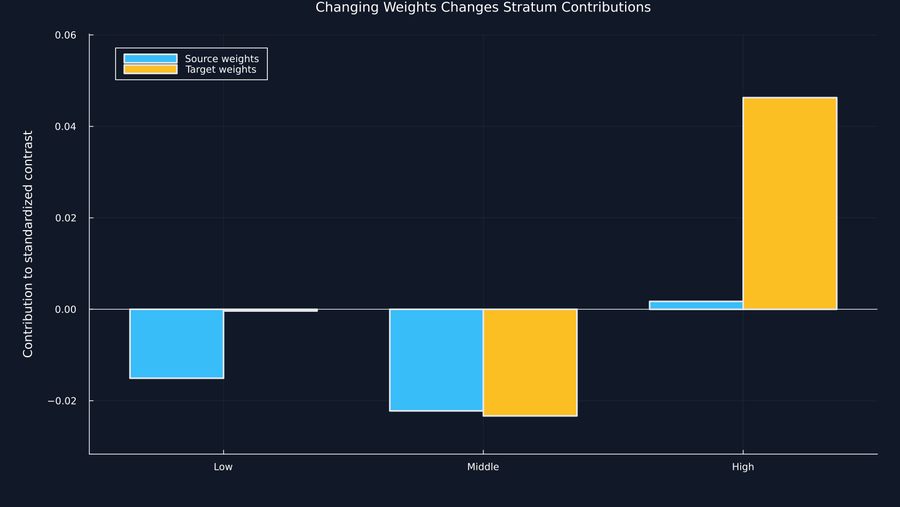

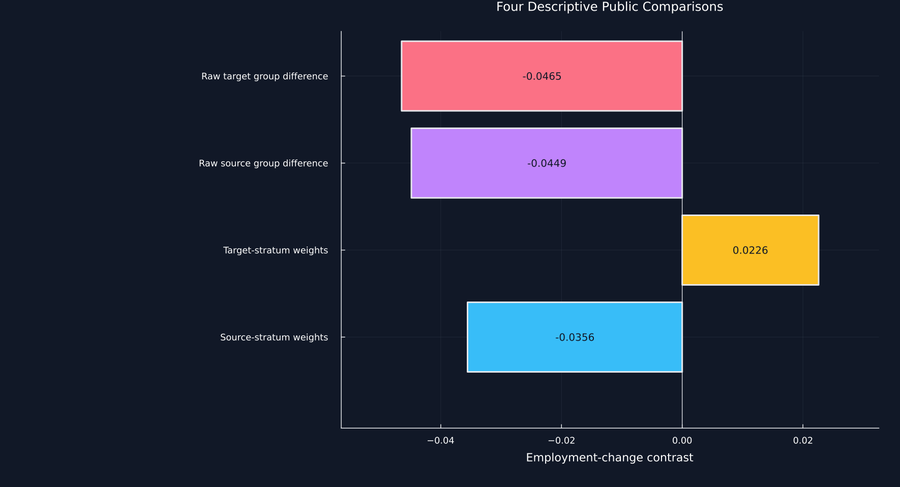

In [3]:
decomposition=public_summary[:,["Stratum","Stratum name","Source contrast","Source probability","Target probability"]]
decomposition[!,"Source contribution"]=decomposition[:,4].*decomposition[:,3]
decomposition[!,"Target contribution"]=decomposition[:,5].*decomposition[:,3]
decomposition[!,"Weight-shift contribution"]=(decomposition[:,5]-decomposition[:,4]).*decomposition[:,3]
table(decomposition,"transport_public_decomposition")
table(decomposition[:,["Stratum name","Source contribution","Target contribution","Weight-shift contribution"]],"transport_public_decomposition_book")
decomposition_check=frame(["Quantity","Value"],[("Source-weighted contrast",sum(decomposition[:,6])),("Target-weighted contrast",sum(decomposition[:,7])),("Direct difference",public_target_effect-public_source_effect),("Sum of weight-shift contributions",sum(decomposition[:,8])),("Identity residual",public_target_effect-public_source_effect-sum(decomposition[:,8]))])
table(decomposition_check,"transport_public_decomposition_check")
public_boundaries = frame(["Object","Supplied by","Does not establish"],[["Source conditional contrasts","Observed source group means within strata","Treatment exchangeability"],["Target stratum weights","Observed target baseline distribution","Conditional effect transportability"],["Target-weighted value","Finite weighted sum","A transported causal effect"],["Support audit","Source counts and target weights","Substantive comparability across populations"]])
table(public_boundaries,"transport_public_boundaries")
contribution_data=decomposition[:,["Stratum","Stratum name","Source contribution","Target contribution"]]
save_data(contribution_data,paths,"transport_public_contributions")
figure=paired_bars(contribution_data[:,2],contribution_data[:,3],contribution_data[:,4],"Changing Weights Changes Stratum Contributions","Contribution to standardized contrast";left_label="Source weights",right_label="Target weights")
save_figure(figure,paths,"transport_public_contributions")
comparison_data=public_effects[:,["Calculation","Value"]]
save_data(comparison_data,paths,"transport_public_effect_comparison")
figure=bar(1:4,comparison_data[:,2];orientation=:h,color=[palette.cyan,palette.amber,"#C084FC",palette.rose],yticks=(1:4,comparison_data[:,1]),xlabel="Employment-change contrast",title="Four Descriptive Public Comparisons",legend=false,size=(1180,640),left_margin=65Plots.mm,xlims=(minimum(comparison_data[:,2])-.01,maximum(comparison_data[:,2])+.01))
vline!(figure,[0.];color=palette.text,linewidth=.9,label="")
for (index,value) in enumerate(comparison_data[:,2])
    annotate!(figure,value/2,index,text(@sprintf("%.4f",value),9,"#111827"))
end
save_figure(figure,paths,"transport_public_effect_comparison")
